<a href="https://colab.research.google.com/github/mdmateen206/Maths-for-ML/blob/main/sts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<BarContainer object of 6 artists>

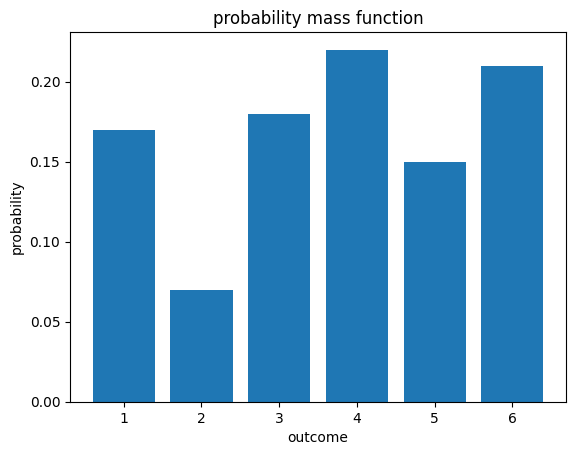

In [ ]:
#probability mass function.....
#one die is roleing at a time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

l=[]
for i in range(100):
  l.append(random.randint(1,6))
len(l)
s=(pd.Series(l).value_counts()/pd.Series(l).value_counts().sum()).sort_index()
s
graphs=plt.bar(s.index,s.values)
plt.xlabel("outcome")
plt.ylabel("probability")
plt.title("probability mass function")
graphs


<BarContainer object of 11 artists>

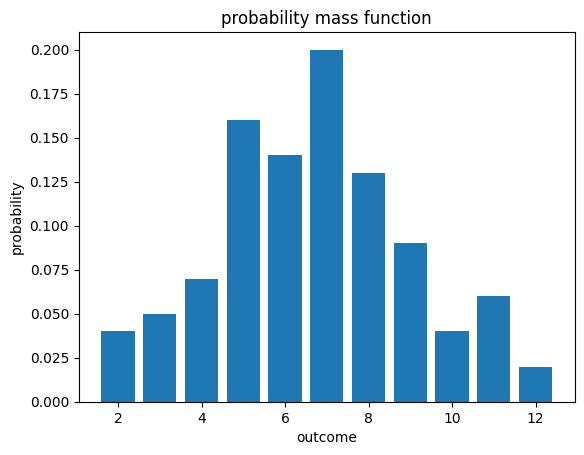

In [ ]:
#2 dies together.....
l=[]
for i in range(100):
  a=random.randint(1,6)
  b=random.randint(1,6)
  l.append(a+b)
len(l)

r=(pd.Series(l).value_counts()/pd.Series(l).value_counts().sum()).sort_index()
g=plt.bar(r.index,r.values)
plt.xlabel("outcome")
plt.ylabel("probability")
plt.title("probability mass function")
g


<Axes: >

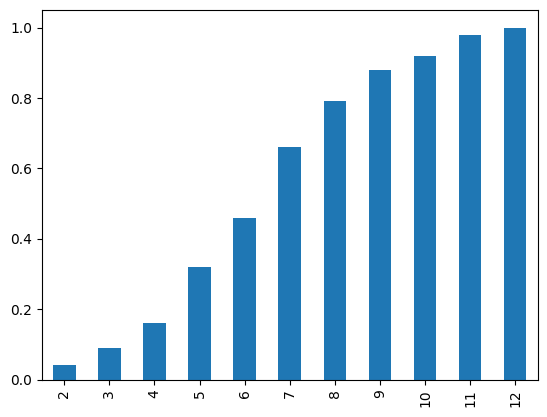

In [ ]:
np.cumsum(r).plot(kind="bar")

(array([  3.,  10.,  56., 143., 255., 253., 180.,  70.,  27.,   3.]),
 array([32.54905895, 36.01484731, 39.48063567, 42.94642402, 46.41221238,
        49.87800074, 53.3437891 , 56.80957746, 60.27536581, 63.74115417,
        67.20694253]),
 <BarContainer object of 10 artists>)

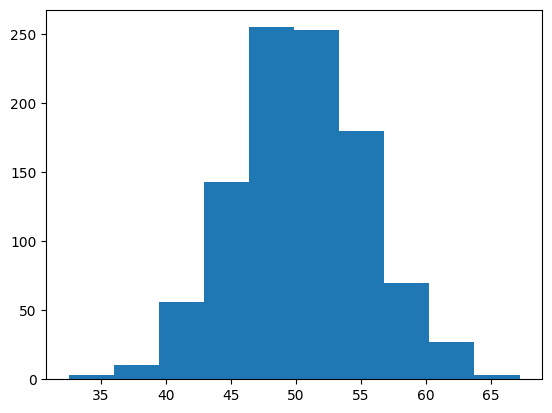

In [ ]:
#probability density function...
#parametric density estimation
import matplotlib.pyplot as plt
from numpy.random import normal
sample=normal(loc=50,scale=5,size=1000)
plt.hist(sample,bins=10)

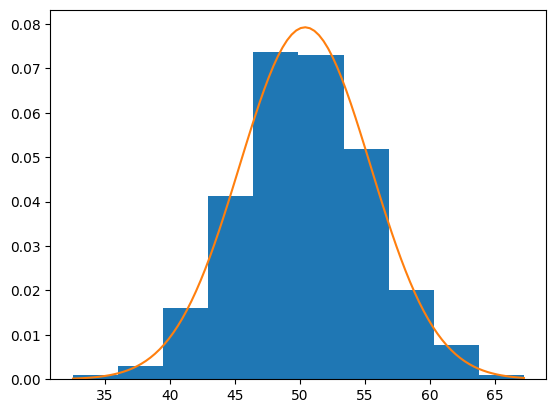

In [ ]:
#calculate mean and std
sample_mean=sample.mean()
sample_std=sample.std()

#fit the distrbution with the above parameter
from scipy.stats import norm
dist=norm(sample_mean,sample_std)

values=np.linspace(sample.min(),sample.max(),100)
probability=[dist.pdf(value) for value in values]
plt.hist(sample,density=True)
plt.plot(values,probability)
plt.show()



(array([ 1.,  3.,  1.,  3.,  1.,  2.,  7.,  6.,  9.,  6., 12., 21., 17.,
        27., 26., 31., 19., 26., 26., 15., 12., 11.,  9., 10., 10., 14.,
        15., 18., 31., 26., 50., 51., 51., 59., 46., 52., 55., 45., 44.,
        35., 26., 21., 13., 13., 12.,  4.,  1.,  2.,  2.,  3.]),
 array([ 5.49028673,  6.49619671,  7.50210669,  8.50801668,  9.51392666,
        10.51983665, 11.52574663, 12.53165662, 13.5375666 , 14.54347658,
        15.54938657, 16.55529655, 17.56120654, 18.56711652, 19.5730265 ,
        20.57893649, 21.58484647, 22.59075646, 23.59666644, 24.60257643,
        25.60848641, 26.61439639, 27.62030638, 28.62621636, 29.63212635,
        30.63803633, 31.64394632, 32.6498563 , 33.65576628, 34.66167627,
        35.66758625, 36.67349624, 37.67940622, 38.6853162 , 39.69122619,
        40.69713617, 41.70304616, 42.70895614, 43.71486613, 44.72077611,
        45.72668609, 46.73259608, 47.73850606, 48.74441605, 49.75032603,
        50.75623602, 51.762146  , 52.76805598, 53.77396597,

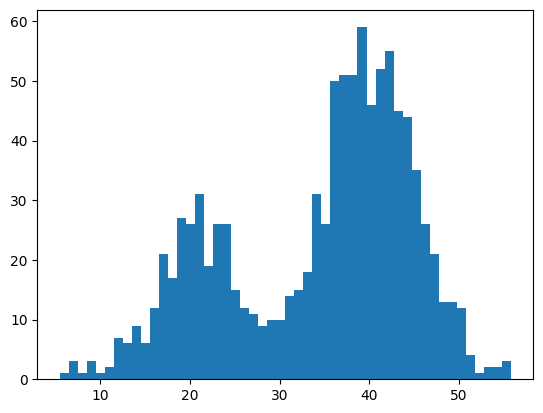

In [ ]:
#non-parametric density function...
from numpy.random import normal
sample1=normal(loc=20,scale=5,size=300)
sample2=normal(loc=40,scale=5,size=700)
sample=np.hstack((sample1,sample2))
plt.hist(sample,bins=50)


In [ ]:
from sklearn.neighbors import KernelDensity
model=KernelDensity(bandwidth=3,kernel="gaussian")

#convert into 2D array
sample=sample.reshape(len(sample), 1)
model.fit(sample)

KernelDensity(bandwidth=3)

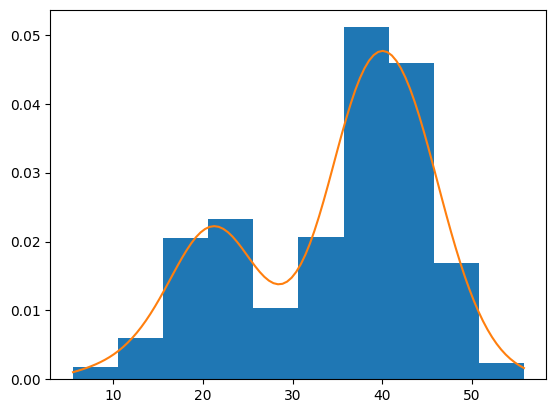

In [ ]:
values=np.linspace(sample.min(),sample.max(),100)
value=values.reshape(len(values),1)

probability=model.score_samples(value)
probability=np.exp(probability)
plt.hist(sample,density=True)
plt.plot(value,probability)
plt.show()